# Group 31: Mobile banking: financial inclusion vs cybersecurity risks

Reproduces every number in the paper. Run from this folder. Sections: 1 data, 2 survey analysis (weighted results and logistic model), 3 peer economies and app reviews, 4 manual classification of fraud-keyword reviews, 5 illustrative financial model.

**Data.** `data/wdi_peers.csv` and `data/app_reviews.csv` come from `fetch_data.py`. The India household microdata (`data/Findex_Microdata_2025_updateIndia.dta`) is not included because of the World Bank's access conditions; see README.txt.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
Path('results').mkdir(exist_ok=True); Path('figures').mkdir(exist_ok=True)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 20)
print(sorted(p.name for p in Path('data').iterdir()))

['Findex_Microdata_2025_updateIndia.dta', 'app_reviews.csv', 'wdi_peers.csv']


## 1. Survey analysis: India Global Findex 2024 microdata (3,000 adults)
Weighted shares by group, then an exploratory weighted logistic model for unsolicited money requests (phone owners).

In [2]:
%run scripts/analysis_group31.py

                                   comparison    n  positives  weighted_percent
                          All adults: account 3000       2710             89.02
                    All adults: anydigpayment 3000       1539             48.46
                             All adults: con1 3000       2145             66.47
                          Phone owners: con18 2141       1321             57.67
                          Phone owners: con21 2145        219              9.35
          Reported unsolicited request: con22  219         45             20.97
         Phone owners, anydigpayment=0: con21  862         46              4.32
         Phone owners, anydigpayment=0: con18  859        416             44.64
         Phone owners, anydigpayment=1: con21 1283        173             13.12
         Phone owners, anydigpayment=1: con18 1282        905             67.39
                            female=1: account 1526       1374             89.25
                      female=1: anydigpa

## 2. Peer economies and app-review keyword coding
Peer values are published World Bank aggregates; India's request share is our microdata estimate. Reviews are public Google Play reviews of five apps.

In [3]:
%run scripts/analysis_extra.py

            economy  year  account_pct_adults  own_phone_pct_adults  phone_lock_pct_phone_owners  unsolicited_money_request_pct_phone_owners
              India  2024                89.0                  66.5                         57.6                                         9.4
              China  2024                89.4                  96.6                          NaN                                         NaN
          Indonesia  2024                56.3                  80.3                         69.1                                        18.5
         Bangladesh  2024                43.3                  82.4                         47.5                                        12.7
           Pakistan  2024                27.3                  62.9                         46.4                                        18.8
             Brazil  2024                86.4                  92.1                         78.0                                        32.4
       South 

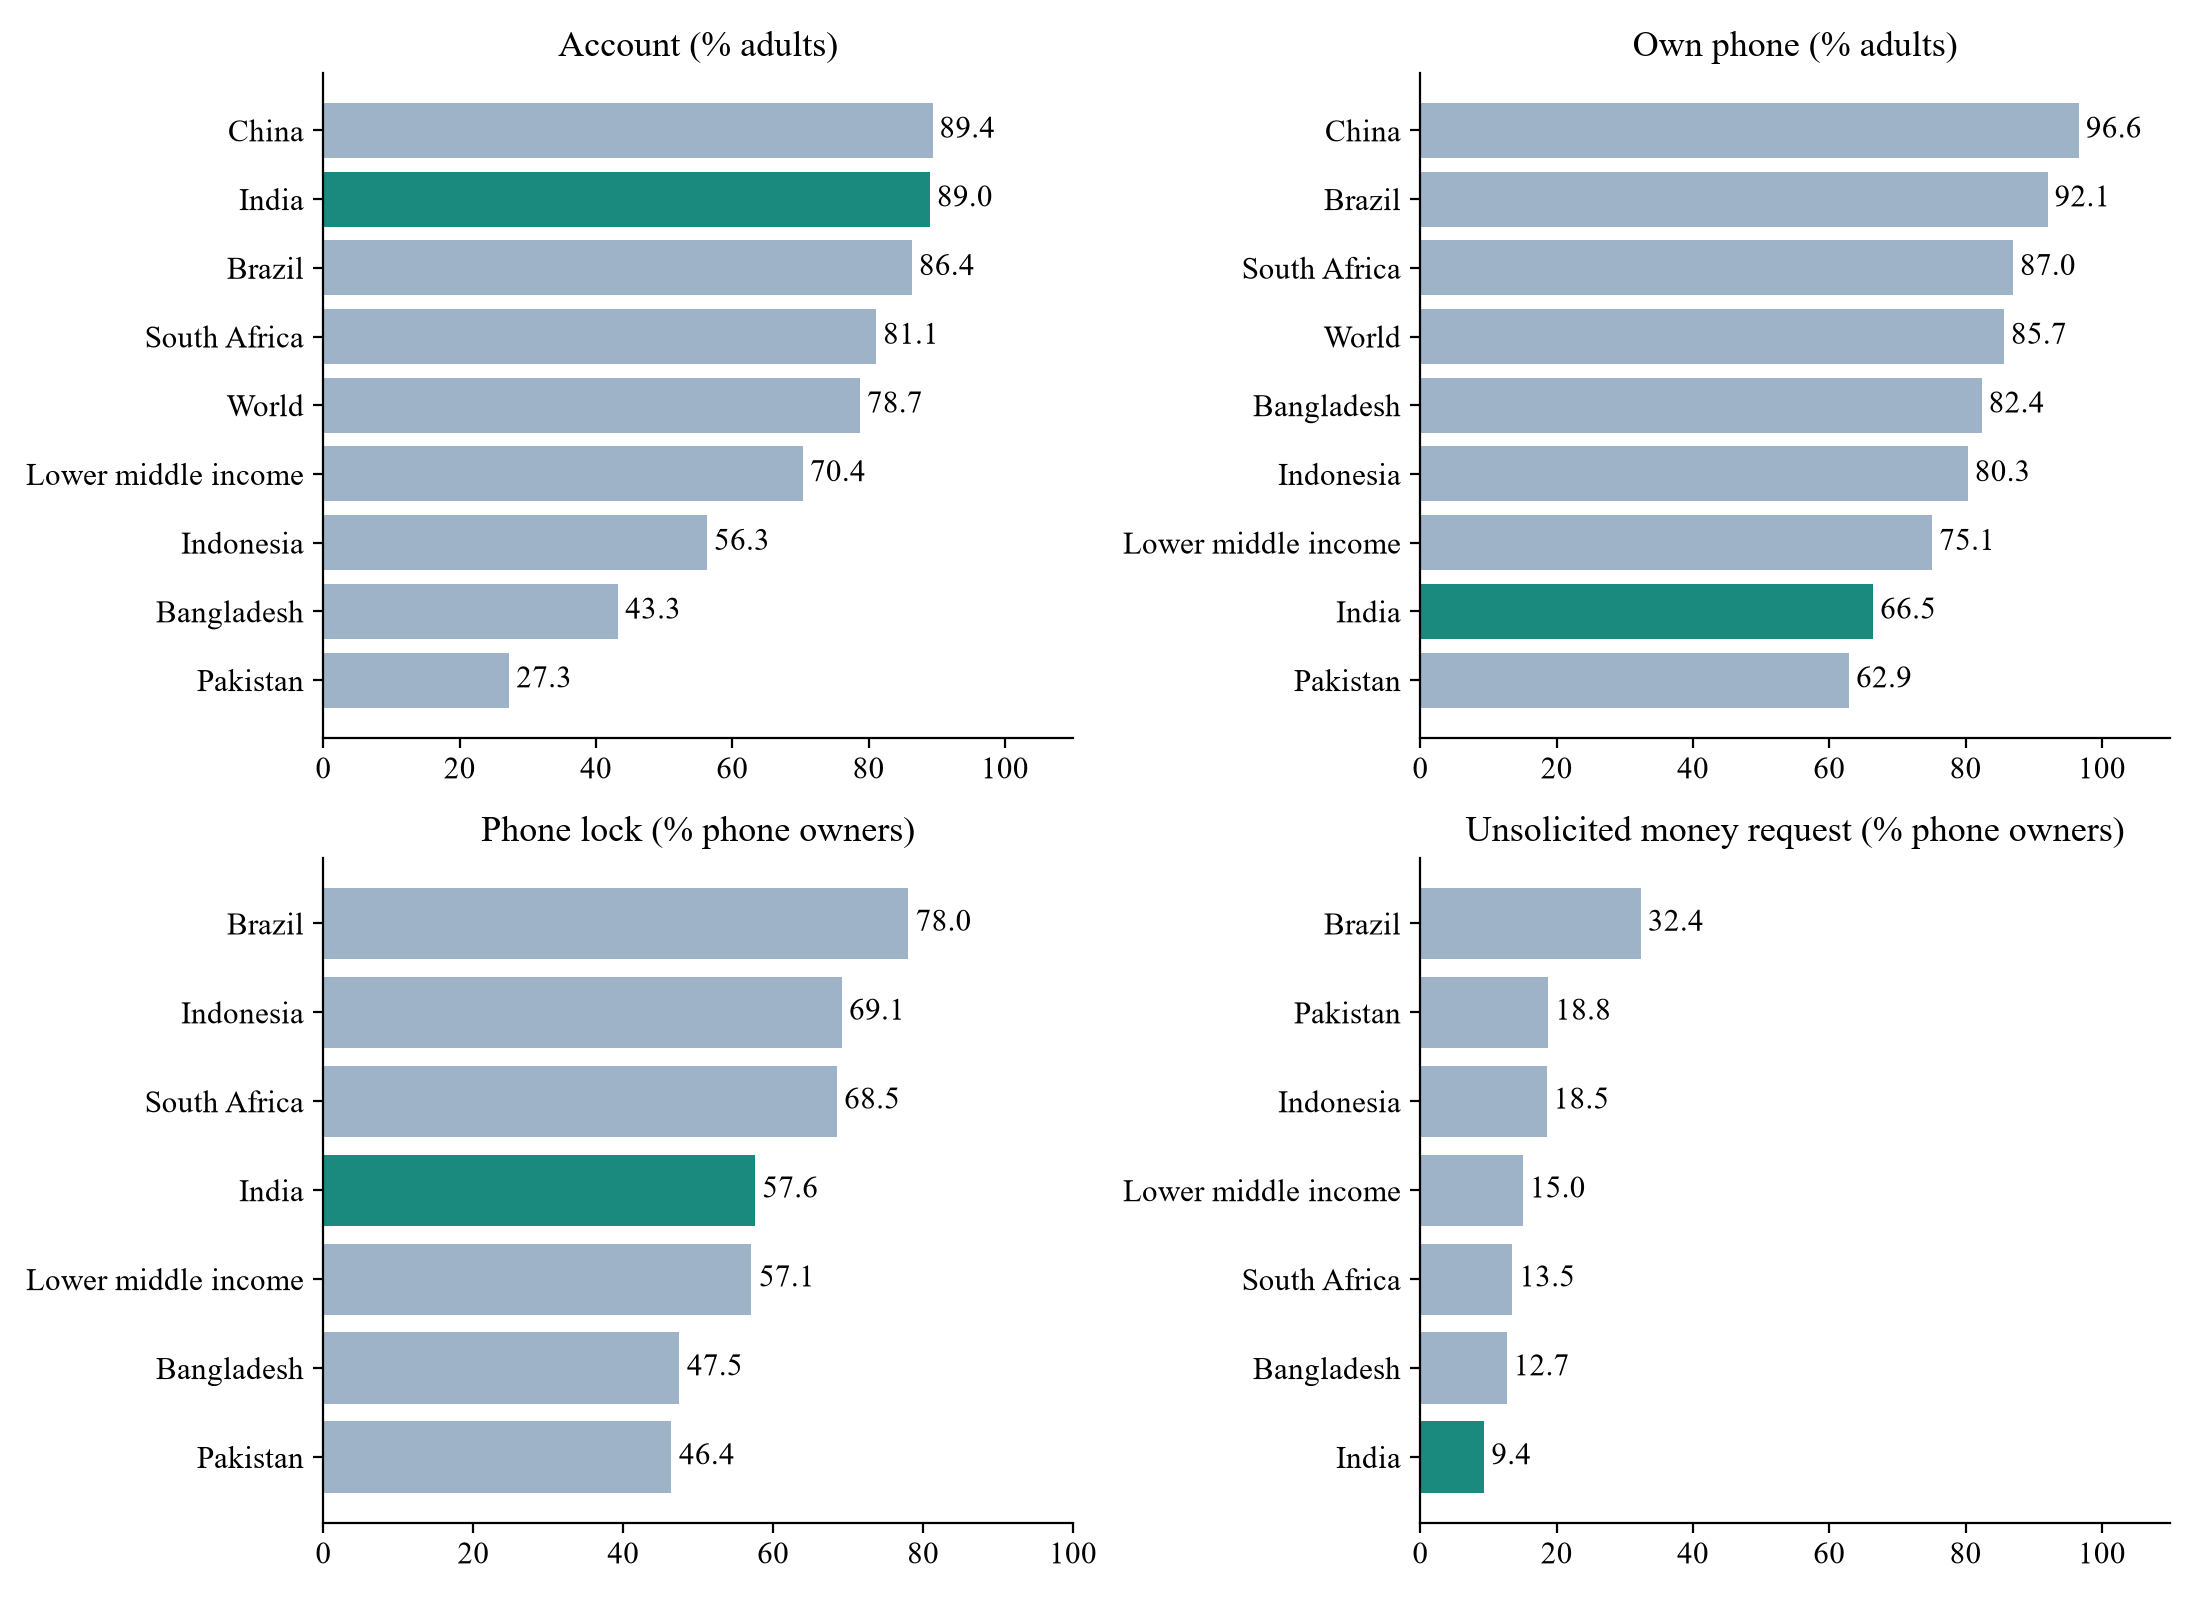

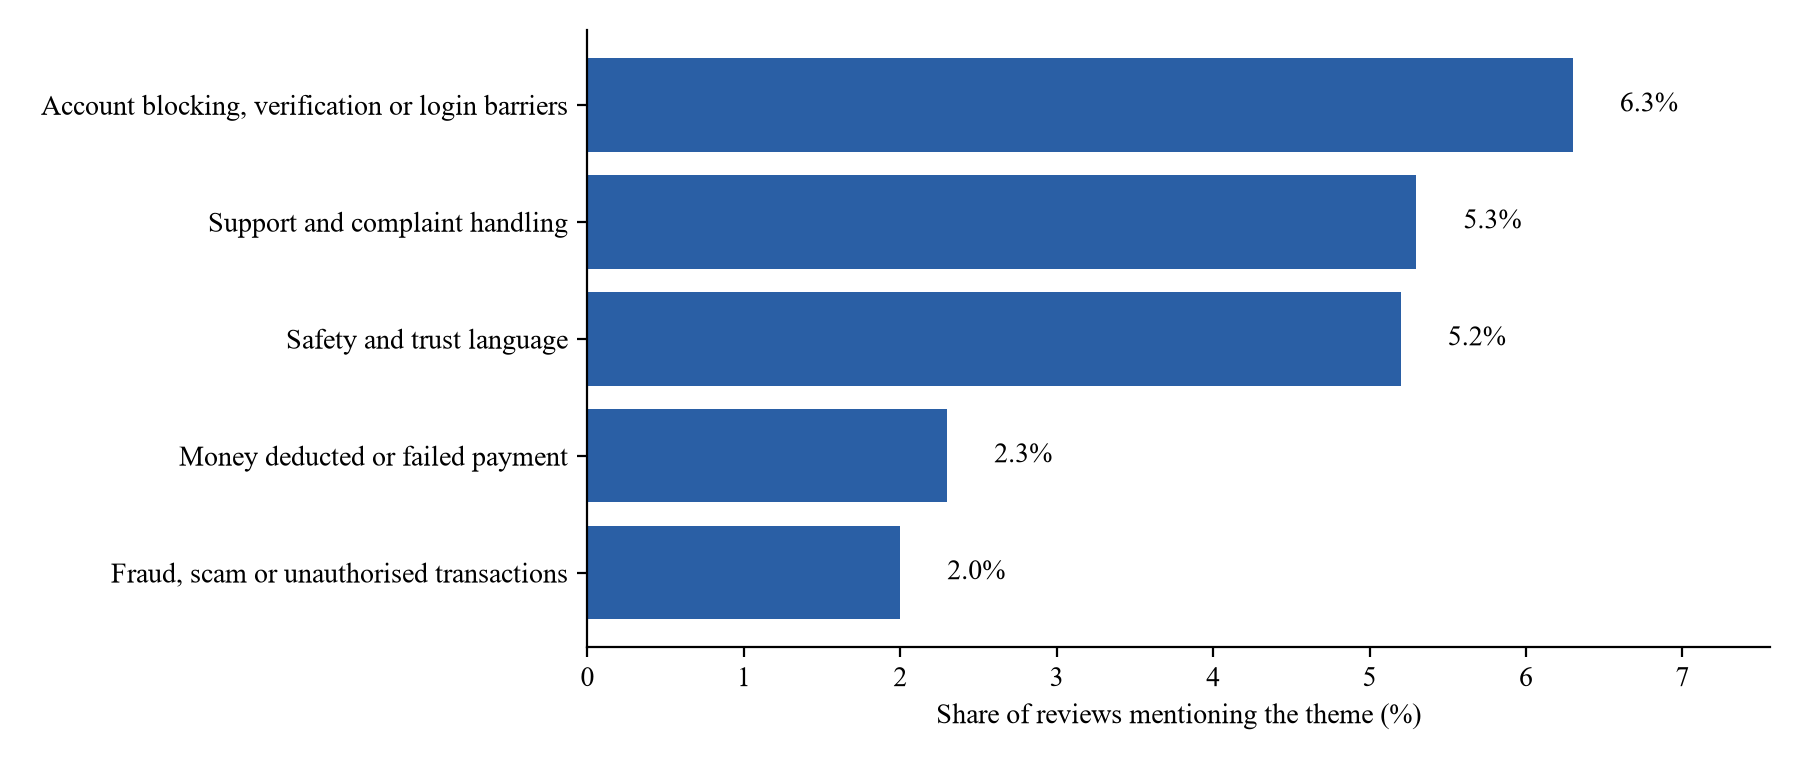

In [4]:
display(Image('figures/figure5.png', width=700)); display(Image('figures/figure6.png', width=700))

## 3. Manual classification of the 118 fraud-keyword reviews
Every review that matched the fraud keywords was read and assigned one category. First pass: one coder; blind AI second pass on all 118 (`results/review_fraud_second_pass.csv`); human coder on a stratified sample of 40 (`results/human_second_coder_partA.csv`). The index lists are in `scripts/manual_coding_fraud_reviews.py`.

In [5]:
%run scripts/manual_coding_fraud_reviews.py

                                                  category  reviews  share_pct
Reward, cashback or offer not honoured (called scam/fraud)       60       50.8
           Money debited, payment failed or refund missing       15       12.7
   Blocked account, mis-selling or poor grievance handling       11        9.3
 Spam, permissions, privacy or intrusive security controls       10        8.5
                  General accusation, no specific incident        9        7.6
                                    Praise or no complaint        7        5.9
Unauthorised access, theft or hacking (reported or feared)        6        5.1
total 118


## 4. Illustrative financial model (assumptions, not findings)
Price INR 50,000 per institution per month, variable cost INR 10,000, acquisition cost INR 2 lakh, fixed cost INR 3 lakh per month. All inputs need pilot validation.

In [6]:
%run scripts/revision_finance.py
print(pd.read_csv('results/financial_projection.csv')[['scenario','year','revenue_lakh','total_cost_lakh','surplus_lakh']].to_string(index=False))

Illustrative financial model verified: 9 projection rows, 9 sensitivity cells, seed total INR 75 lakh.
    scenario  year  revenue_lakh  total_cost_lakh  surplus_lakh
Conservative     1           9.6            46.40        -36.80
Conservative     2          33.6            63.60        -30.00
Conservative     3          67.2            84.64        -17.44
        Base     1          24.0            56.80        -32.80
        Base     2          84.0            84.00          0.00
        Base     3         180.0           127.84         52.16
  Optimistic     1          43.2            67.20        -24.00
  Optimistic     2         158.4           109.60         48.80
  Optimistic     3         349.2           176.04        173.16


## 6. Apple App Store reviews (second platform)
The same five apps, India storefront, from Apple's public customer-review feed (newest reviews only, so the window differs from Google Play). Reviewer names are not stored.

In [ ]:
# python scripts/fetch_appstore.py   (re-fetching returns the newest reviews at that time; the snapshot used in the paper is data/appstore_reviews.csv)
print(open('data/appstore_reviews.csv').readline().strip())

app,date,rating,version,title,text

2090 reviews saved to data/appstore_reviews.csv
              n  mean_rating       first        last
app                                                 
BHIM        499         2.15  2026-04-30  2026-11-18
Google Pay  370         3.83  2026-09-29  2026-11-18
Paytm       400         4.08  2026-10-02  2026-11-18
PhonePe     328         4.00  2026-10-19  2026-11-18
SBI YONO    493         3.01  2026-08-01  2026-11-18


In [ ]:
%run scripts/analysis_appstore.py

                                           theme  reviews  share_pct  mean_rating  one_star_share_pct
        Fraud, scam or unauthorised transactions       57        2.7         1.51                86.0
                Money deducted or failed payment       32        1.5         1.41                87.5
                  Support and complaint handling      133        6.4         1.55                78.2
Account blocking, verification or login barriers      162        7.8         1.80                70.4
                       Safety and trust language      134        6.4         3.99                23.1
{'n_reviews': 2090, 'apps': {'BHIM': 499, 'SBI YONO': 493, 'Paytm': 400, 'Google Pay': 370, 'PhonePe': 328}, 'date_min': '2026-04-30', 'date_max': '2026-11-18', 'mean_rating': np.float64(3.31), 'any_theme_pct': np.float64(20.7), 'fraud_theme_mean_rating': np.float64(1.51), 'non_fraud_mean_rating': np.float64(3.36)}


The 57 fraud-keyword App Store reviews were classified by one coder and re-classified in a blind second pass by a separate AI instance; see `results/appstore_fraud_manual_codes.csv` (columns `manual_category`, `second_pass`).

In [ ]:
m = pd.read_csv('results/appstore_fraud_manual_codes.csv')
agree = (m.manual_category == m.second_pass).sum()
print(f'agreement {agree}/{len(m)} = {100*agree/len(m):.1f}%')
print(m.manual_category.value_counts().to_string())

agreement 47/57 = 82.5%
manual_category
Reward, cashback or offer not honoured (called scam/fraud)    17
Money debited, payment failed or refund missing               11
Blocked account, mis-selling or poor grievance handling       10
Spam, permissions, privacy or intrusive security controls      7
General accusation, no specific incident                       6
Praise or no complaint                                         4
Unauthorised access, theft or hacking (reported or feared)     2


## 7. Design-effect sensitivity for the logistic model
The public file has no strata or PSU identifiers. `scripts/analysis_sensitivity.py` reports the Kish design effect from the weights and re-reports the intervals after inflating the variance for assumed extra design effects of 1.5, 2 and 3. Run it from the folder that contains `data/Findex_Microdata_2025_updateIndia.dta`.

In [ ]:
# python scripts/analysis_sensitivity.py results
print(open('results/Group_31_design_sensitivity_note.txt').read())

n=2145; Kish design effect from weights=1.429; effective n=1501
Intervals inflate the sandwich variance by the stated extra design effect (assumed clustering); not design-based.
 extra_design_effect           variable  odds_ratio  low_95  high_95  excludes_1
                 1.0    Digital payment       3.448   2.244    5.298        True
                 1.0             Female       0.466   0.316    0.689        True
                 1.0 Tertiary education       1.696   1.028    2.799        True
                 1.5    Digital payment       3.448   2.037    5.835        True
                 1.5             Female       0.466   0.289    0.752        True
                 1.5 Tertiary education       1.696   0.918    3.133       False
                 2.0    Digital payment       3.448   1.878    6.330        True
                 2.0             Female       0.466   0.268    0.809        True
                 2.0 Tertiary education       1.696   0.835    3.445       False
            

## 8. Bank mobile-banking app reviews
Mobile banking is delivered mainly through banks' own apps, so reviews of eight bank apps were collected (Google Play: ICICI iMobile, Axis Mobile, Kotak Bank, bob World, Canara ai1, IDFC FIRST; App Store: HDFC Bank, ICICI iMobile, Axis Mobile, Kotak 811, PNB ONE, bob World). Same theme dictionaries as section 3, plus a security-friction dictionary.

In [ ]:
# python scripts/fetch_bankapps.py   (re-fetching returns the newest reviews at that time; the snapshots used in the paper are data/bankapps_*.csv)
print('stored snapshots:', [f for f in __import__('os').listdir('data') if f.startswith('bankapps')])

ICICI iMobile 1500
Axis Mobile 1500
Kotak Bank 1500
bob World 1500
Canara ai1 1500
IDFC FIRST 1500
Play 4279
                  n  mean       first        last
app                                              
Axis Mobile     624  3.14  2026-11-02  2026-11-18
Canara ai1      689  3.16  2026-11-05  2026-11-19
ICICI iMobile   671  2.58  2026-10-27  2026-11-19
IDFC FIRST      413  3.61  2026-11-01  2026-11-19
Kotak Bank      804  2.14  2026-09-17  2026-11-18
bob World      1078  1.68  2026-09-28  2026-11-19
App Store 1961
                 n  mean       first        last
app                                             
Axis Mobile    493  1.78  2026-08-13  2026-11-18
HDFC Bank      100  1.85  2026-10-02  2026-11-17
ICICI iMobile  470  2.68  2026-10-07  2026-11-18
Kotak 811      180  3.20  2026-07-19  2026-11-18
PNB ONE        291  2.41  2026-06-15  2026-11-17
bob World      427  2.49  2026-06-05  2026-11-18


In [ ]:
%run scripts/analysis_bankapps.py

                                                                                 theme  reviews  share_pct  mean_rating  one_star_share_pct
                                              Fraud, scam or unauthorised transactions       65        1.0         1.22                92.3
                                                      Money deducted or failed payment       26        0.4         1.73                73.1
                                                        Support and complaint handling      345        5.5         1.60                80.0
                                      Account blocking, verification or login barriers      370        5.9         1.45                81.4
                                                             Safety and trust language      213        3.4         2.70                51.2
Security-friction prompts (device binding, SIM, root, VPN, screen sharing, biometrics)      149        2.4         1.59                77.2
{'n_reviews': 6240, 

In [ ]:
m = pd.read_csv('results/bankapps_fraud_manual_codes.csv')
agree = (m.manual_category == m.second_pass).sum()
print(f'bank-app fraud-keyword reviews: {len(m)}; first vs blind second pass agreement {agree}/{len(m)} = {100*agree/len(m):.1f}%')
print(m.manual_category.value_counts().to_string())

bank-app fraud-keyword reviews: 65; first vs blind second pass agreement 57/65 = 87.7%
manual_category
Blocked account, mis-selling or poor grievance handling       25
General accusation, no specific incident                      14
Spam, permissions, privacy or intrusive security controls     13
Money debited, payment failed or refund missing                4
Unauthorised access, theft or hacking (reported or feared)     3
Reward, cashback or offer not honoured (called scam/fraud)     3
Praise or no complaint                                         3


## 9. Inclusion vs cybersecurity risk by group
For 18 demographic groups: inclusion (digital payment use among all adults in the group), risk (reported unsolicited money request among phone owners) and protection (device lock). Descriptive; groups overlap. Reads the audited results, so no microdata is needed.

In [ ]:
%run scripts/analysis_inclusion_risk.py

dimension                group  payment_use_pct  payment_n  request_exposure_pct  exposure_n  lock_use_pct  lock_n
      Sex                Women             42.7       1526                   5.7         920          50.3     919
      Sex                  Men             54.1       1474                  11.8        1225          62.7    1222
      Age                15–24             43.5        722                   8.3         497          75.7     497
      Age                25–39             51.3       1134                  11.1         894          62.7     893
      Age                40–59             46.6        858                   9.8         599          43.6     597
      Age                  60+             56.6        286                   4.1         155          22.9     154
Education      Primary or less             40.7       1680                   8.4        1011          41.2    1007
Education            Secondary             62.7       1016                   9.0

In [ ]:
from IPython.display import Image, display
display(Image('figures/figure7_inclusion_vs_risk.png', width=700))

## 10. Sensitivity to language (Hindi / Hinglish)
The keyword dictionaries are English only and kept unchanged. This check lists the additional reviews an extended dictionary would flag; they were read and classified in `results/hinglish_extra_reviews.csv`.

In [ ]:
%run scripts/analysis_hinglish.py

{
  "Play payment apps": {
    "reviews": 5758,
    "english_fraud_keyword": 118,
    "extra_hinglish_only": 23
  },
  "App Store payment apps": {
    "reviews": 2090,
    "english_fraud_keyword": 57,
    "extra_hinglish_only": 3
  },
  "Play bank apps": {
    "reviews": 4279,
    "english_fraud_keyword": 46,
    "extra_hinglish_only": 13
  },
  "App Store bank apps": {
    "reviews": 1961,
    "english_fraud_keyword": 19,
    "extra_hinglish_only": 2
  }
}


## 11. Significance tests
RQ3 (Fisher exact on unweighted counts) and bank-vs-payment-app comparisons (chi-square with Holm adjustment; Fisher exact for the manual categories).

In [ ]:
%run scripts/analysis_tests.py

                                                                                                                  test                    method  statistic   p_raw  p_holm
                                                                      RQ3: sent money, lock (39/170) vs no lock (6/49) Fisher exact (unweighted)        2.1    0.11     NaN
                           Bank vs payment apps, theme: Fraud, scam or unauthorised transactions (65/6240 vs 175/7848)           chi-square, 2x2         29 6.2e-08 2.5e-07
                                   Bank vs payment apps, theme: Money deducted or failed payment (26/6240 vs 165/7848)           chi-square, 2x2         74 8.4e-18   5e-17
                                    Bank vs payment apps, theme: Support and complaint handling (345/6240 vs 439/7848)           chi-square, 2x2       0.03    0.87    0.87
                          Bank vs payment apps, theme: Account blocking, verification or login  (370/6240 vs 527/7848)           chi-square,

## 5. Key results used in the paper
Account ownership 89.0%, digital payment 48.5%, phone lock 57.7% of phone owners, adjusted odds ratio for payment users 3.45 (approx. 95% interval 2.24 to 5.30), India account ownership second among seven peer economies, 118 fraud-keyword reviews of 5,758 of which 6 describe unauthorised access or theft, base-case break-even at 8 paying institutions.